## Task 1.0 (Warm-up): Adding dissopation one ingredient at a time  

### (a) Single-photon loss

In [ ]:
import dynamiqs as dq
import jax
import jax.numpy as jnp # the JAX version of numpy
from matplotlib import pyplot as plt

jax.devices()

dq.set_device('cpu')

dq.set_precision('single')

In [4]:
# 1. Parameters: time is in microseconds
n = 30                       # retain photon levels 0 through 29
Delta = 2 * jnp.pi * 1.0      # Delta / (2*pi) = 1 MHz
kappa = 2 * jnp.pi * 1.0      # kappa / (2*pi) = 1 MHz
alpha0 = 2.0                  # initial coherent-state amplitude
T = 1.0                      # simulate for 1 microsecond


In [13]:
# 2. Operators
a = dq.destroy(n)
number_op = a.dag() @ a       # photon-number operator
H = Delta * number_op         # positive sign, as in the challenge

# 3. Photon-loss process
jump_ops = [jnp.sqrt(kappa) * a]

# 4. Initial state and times to save
psi0 = dq.coherent(n, alpha0)
t_save = jnp.linspace(0.0, T, 201)


In [15]:

# 5. Simulate and calculate the mean photon number
result = dq.mesolve(
    H,
    jump_ops,
    psi0,
    t_save,
    exp_ops=[number_op],
)

n_sim = result.expects[0].real

# 6. Analytic prediction
n_exact = abs(alpha0)**2 * jnp.exp(-kappa * t_save)


|██████████| 100.0% ◆ elapsed 8.05ms ◆ remaining 0.00ms


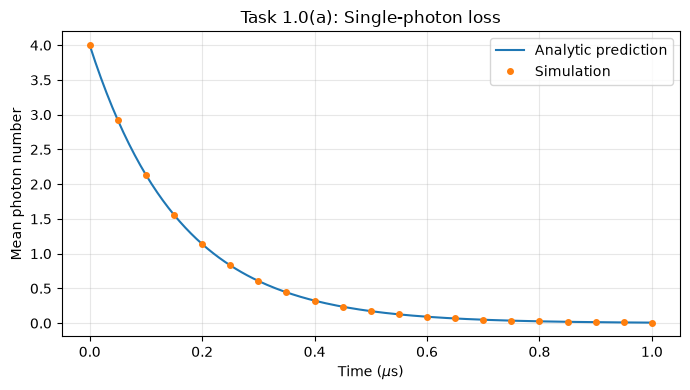

In [16]:

# 7. Overlay the two results
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(t_save, n_exact, label="Analytic prediction")
ax.plot(
    t_save[::10],
    n_sim[::10],
    "o",
    markersize=4,
    label="Simulation",
)

ax.set_xlabel(r"Time ($\mu$s)")
ax.set_ylabel("Mean photon number")
ax.set_title("Task 1.0(a): Single-photon loss")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### (b) Pure two-photon loss 

In [18]:
# 1. Calculate the two-photon loss rate
g2 = 2 * jnp.pi * 0.763        # challenge parameter
kappa_b = 2 * jnp.pi * 2.6     # challenge parameter
kappa_2 = 4 * g2**2 / kappa_b  # approximately 5.6275 per microsecond

# 2. Zero Hamiltonian and ONLY two-photon loss
H_b = dq.zeros(n)
jump_ops_b = [jnp.sqrt(kappa_2) * (a @ a)]

# 3. Run for 2 microseconds as a starting duration
T_b = 2.0
t_save_b = jnp.linspace(0.0, T_b, 401)

# psi0 is still the coherent state with amplitude 2 from part (a)
result_b = dq.mesolve(
    H_b,
    jump_ops_b,
    psi0,
    t_save_b,
    exp_ops=[number_op],
)

n_sim_b = result_b.expects[0].real

|██████████| 100.0% ◆ elapsed 160.98ms ◆ remaining 0.00ms 


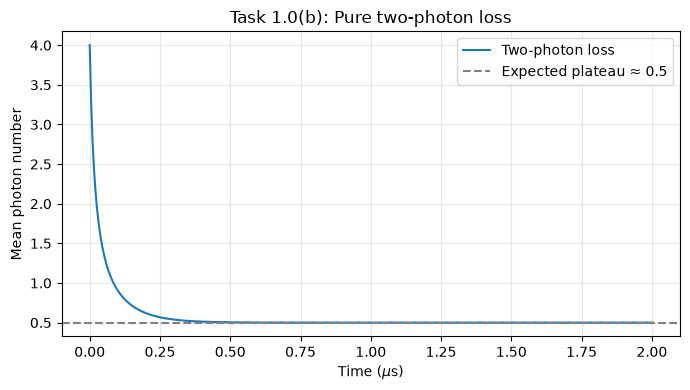

Final mean photon number: 0.4998306930065155
Variation over final quarter: 1.4901161193847656e-07


In [19]:
# 4. Expected final photon number, from parity conservation
n_final_expected = (
    1 - jnp.exp(-2 * abs(alpha0)**2)
) / 2

# 5. Plot the simulation and the expected final plateau
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(t_save_b, n_sim_b, label="Two-photon loss")
ax.axhline(
    float(n_final_expected),
    linestyle="--",
    color="gray",
    label="Expected plateau ≈ 0.5",
)

ax.set_xlabel(r"Time ($\mu$s)")
ax.set_ylabel("Mean photon number")
ax.set_title("Task 1.0(b): Pure two-photon loss")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 6. Check whether the photon number has stopped changing
tail = n_sim_b[3 * len(n_sim_b) // 4:]

print("Final mean photon number:", float(n_sim_b[-1]))
print("Variation over final quarter:",
      float(jnp.max(tail) - jnp.min(tail)))

### (c) 

In [29]:
dq.set_precision("double")

In [33]:
g2 = 2 * jnp.pi * 0.763
kappa_b = 2 * jnp.pi * 2.6
kappa_a = 2 * jnp.pi * 9.3e-3
kappa_2 = 4 * g2**2 / kappa_b

na = 30
alpha = 2.1

a = dq.destroy(na)
number_op = a.dag() @ a
identity = dq.eye(na)
H = dq.zeros(na)
psi0 = dq.fock(na, 0)
tsave = jnp.linspace(0.0, 2.0, 201)

|██████████| 100.0% ◆ elapsed 62.52ms ◆ remaining 0.00ms
|██████████| 100.0% ◆ elapsed 237.47ms ◆ remaining 0.00ms  
|██████████| 100.0% ◆ elapsed 1.04s ◆ remaining 0.00ms     


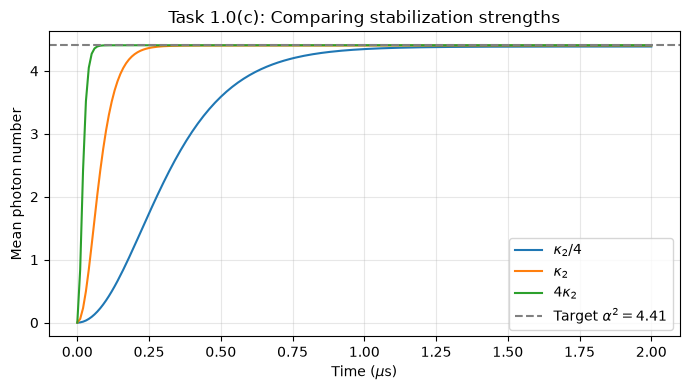

In [34]:
factors = [0.25, 1.0, 4.0]
labels = [
    r"$\kappa_2/4$",
    r"$\kappa_2$",
    r"$4\kappa_2$",
]

results = {}  # keep each result for later Wigner plots

fig, ax = plt.subplots(figsize=(7, 4))

for factor, label in zip(factors, labels):

    # Select the two-photon stabilization strength
    current_kappa_2 = factor * kappa_2

    # Jump operator 1: engineered cat stabilization
    L2 = jnp.sqrt(current_kappa_2) * (
        a @ a - alpha**2 * identity
    )

    # Jump operator 2: unwanted single-photon loss
    L1 = jnp.sqrt(kappa_a) * a

    # Run this case, starting from vacuum again
    res = dq.mesolve(
        H,
        [L2, L1],
        psi0,
        tsave,
        exp_ops=[number_op],
    )

    results[factor] = res

    # Extract and plot the mean photon number
    photon_number = res.expects[0].real
    ax.plot(tsave, photon_number, label=label)

# Reference line showing the target photon number
ax.axhline(
    alpha**2,
    color="gray",
    linestyle="--",
    label=r"Target $\alpha^2 = 4.41$",
)

ax.set_xlabel(r"Time ($\mu$s)")
ax.set_ylabel("Mean photon number")
ax.set_title("Task 1.0(c): Comparing stabilization strengths")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()